# 회귀 스위트

**이 노트북에서 할 일**

1. 평가 사례 세 건을 이전 판 답과 이후 판 답으로 한 번씩 판정 받습니다.
2. 두 판의 점수를 질문 번호마다 짝지어 나란히 봅니다.
3. 평균만 보는 검사가 깨진 사례를 놓치는 모습을 봅니다(Before).
4. 사례마다 짝지어 보는 검사로 깨진 사례를 찾아 이후 판을 막습니다(After).

**준비물** — 이 절은 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
평가 모델 `gpt-5.4-mini`에 보내는 요청은 여섯 번이고 임베딩 요청은 없습니다.
두 판마다 사례 세 건을 한 번씩 판정하므로 여섯 번입니다.
예상 비용은 미화 0.02달러 아래이고 실제 청구 금액과는 다를 수 있습니다.

읽는 파일은 이 챕터 자료 파일 하나이고 새로 쓰는 파일은 없습니다.
교재 출력을 만든 실행에서는 노트북 전체가 약 7초 만에 끝났습니다.

이후 판의 답 두 개는 자료 파일에 없고 이 절에서 만든 답입니다.
평균은 그대로인데 한 사례가 깨지는 모양을 보이려고 정한 답입니다.

**기준 버전** — 첫 셀에서 LangChain 1.4.0과 langchain-openai 1.6.1을 설치합니다.
키를 읽는 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~8절을 읽습니다.
두 판을 같은 스위트로 판정하고, 평균만 보는 검사와 짝지어 보는 검사를 견주는 자리입니다.
9절은 손으로 적은 작은 예로 두 검사를 확인합니다.
10절은 값 바꿔 보기이고 9절과 함께 실습 시간에 실행합니다.

실습 폴더 `labs/part4/ch15-evaluation-advanced`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 파란 상자 회귀 스위트 한 벌 사례 세 건 Q002 Q006 Q090 판정 머리글 rag-judge-v1.0.0 평가 모델 gpt-5.4-mini와 초록 상자 이전 판 답 자료 파일 rag-answer-v1.0.0, 초록 상자 이후 판 답 Q002 Q090 두 답을 바꿈이 나란히 있고 셋이 모두 보라 상자 gpt-5.4-mini 판마다 판정 세 번으로 모인 뒤 노란 상자 질문 번호마다 점수 짝 이전 판 이후 판을 지나 파란 상자 짝지어 보는 검사 1에서 0이 된 사례가 있으면 이후 판을 막음으로 이어지는 그림](attachment:07-1-같은-스위트로-두-판을-판정.png)

위에서 아래로 읽습니다. 맨 위 파란 스위트와 초록 두 판의 답이 모두 같은 보라 평가 모델로 들어갑니다.
판마다 나온 점수를 질문 번호마다 짝지어 노란 상자에 두고, 맨 아래 파란 검사가 깨진 사례를 찾습니다.
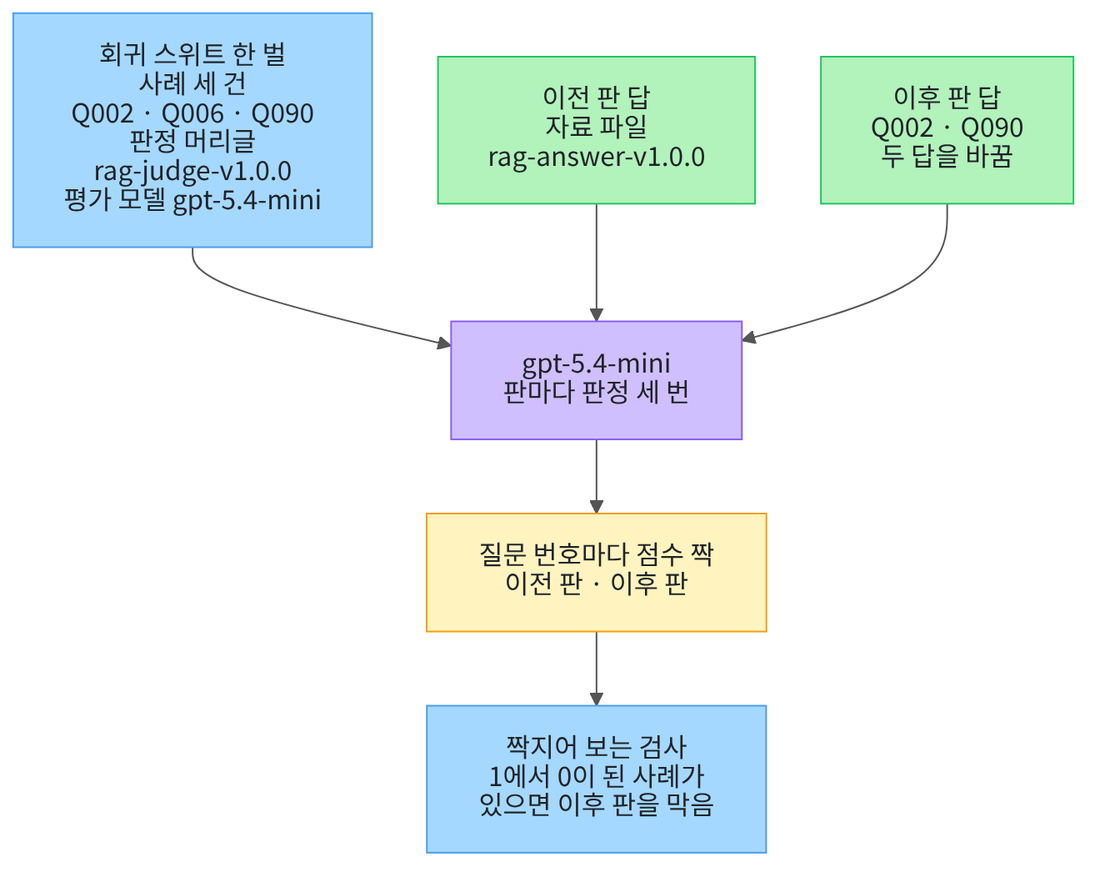

## 1. 준비

첫 셀은 패키지 세 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3


**결과 읽기** — 설치가 끝나면 판 번호 세 줄이 보입니다.
출력 줄 `langchain: 1.4.0`과 `langchain-openai: 1.6.1`이 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-21에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 불러오고 앞에서 배운 함수 넷을 도구 파일에서 가져옵니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 02절 `build_judge_prompt()`와 03절 `score_cases()`를 가져옵니다.
04절 `scores_of()`와 06절 `average()`도 가져옵니다.

In [2]:
# 자료 읽기·폴더 확인에 쓸 이름과 모델을 준비하는 이름을 불러옵니다
import json
import os

from langchain.chat_models import init_chat_model

# Ch 15 02·03·04·06절 함수 넷을 도구 파일에서 가져옵니다
from rag_tools import average, build_judge_prompt, score_cases, scores_of

print("불러온 이름:", "json", "os", "init_chat_model")

불러온 이름: json os init_chat_model


**결과 읽기** — 출력 줄 `불러온 이름: json os init_chat_model`로 이름 세 개를 불러왔습니다.
도구 파일에서 가져온 함수 넷은 출력하지 않습니다.
함수 `scores_of`와 `average`는 04절과 06절 본문 그대로 도구 파일에 옮겼고, 인자도 그때와 같습니다.

## 2. 키와 모델 준비

이 절도 02~06절과 같은 평가 모델 `gpt-5.4-mini`를 부릅니다.
모델을 만드는 설정 값도 06절과 같습니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도 판정 점수와 까닭이 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-21에 이 모델로 실행한 결과입니다.

## 3. 사례와 판정 머리글

회귀(regression)는 판을 바꾼 뒤 전에 통과하던 사례가 다시 실패하는 일입니다.
Ch 2 08절의 회귀 테스트는 고친 결함이 다시 생기는지 확인하려고 남겨 둔 테스트였습니다.
이 절은 같은 생각을 평가 모델의 판정 점수에 씁니다.

먼저 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.
01~06절과 같은 자리 찾기 셀입니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch15-evaluation-advanced/data"):
        root_path = candidate
        break
print("찾은 프로젝트 맨 위:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

찾은 프로젝트 맨 위: .


**결과 읽기** — 출력 줄 `찾은 프로젝트 맨 위:` 뒤에 점 하나나 위로 올라가는 자리가 보입니다.

다음 셀은 06절과 같은 방법으로 이 챕터 자료 파일을 읽습니다.
사례마다 질문 번호도 모아 둡니다.

In [6]:
# 이 챕터 자료 파일을 읽어 평가 사례 목록을 만들고 질문 번호를 모읍니다(읽기만 합니다)
data_path = root_path + "/labs/part4/ch15-evaluation-advanced/data"
with open(data_path + "/evaluation-cases.json", encoding="utf-8") as file:
    case_file = json.loads(file.read())
cases = case_file["cases"]
case_qids = []
for case in cases:
    case_qids.append(case["qid"])
print("평가 사례 수:", len(cases))
print("질문 번호:", case_qids)

평가 사례 수: 3
질문 번호: ['Q002', 'Q006', 'Q090']


**결과 읽기** — 출력 줄 `평가 사례 수: 3`으로 사례는 세 건입니다.
출력 줄 `질문 번호: ['Q002', 'Q006', 'Q090']`이 이 절에서 두 판을 견줄 사례입니다.

다음 셀은 02절 근거 충실도의 판정 머리글을 다시 적습니다.
06절에서 다시 적은 머리글과 같은 코드입니다.

In [7]:
# 02절 근거 충실도의 두 칸 짝과 판정 머리글 rag-judge-v1.0.0을 다시 적습니다
ground_pair = {"답": "response", "근거 문서": "context"}
ground_rule = "답이 근거 문서로 뒷받침되면 1, 아니면 0을 판정하세요."
output_rule = 'JSON만 출력하세요: {"score": 0 또는 1, "reason": "한 문장"}.'
judge_version = "rag-judge-v1.0.0"
judge_head = ground_rule + "\n" + output_rule
print("판 이름:", judge_version)
print("머리글:")
print(judge_head)

판 이름: rag-judge-v1.0.0
머리글:
답이 근거 문서로 뒷받침되면 1, 아니면 0을 판정하세요.
JSON만 출력하세요: {"score": 0 또는 1, "reason": "한 문장"}.


**결과 읽기** — 출력 줄 `판 이름: rag-judge-v1.0.0`은 02절이 붙인 판 이름입니다.
라벨 줄 `머리글:` 아래 두 줄이 기준 문장과 출력 모양입니다.
이 머리글은 두 판을 판정할 때 한 글자도 바꾸지 않습니다.

## 4. 이전 판 점수와 기준선

이 절에서 견줄 두 판은 답 쪽의 판입니다.
이전 판은 자료 파일에 적힌 답 세 개입니다.
다음 셀은 사례마다 답을 쓴 모델과 답의 판 이름을 봅니다.

In [8]:
# 이전 판은 자료 파일에 적힌 답 세 개입니다: 사례마다 답을 쓴 모델과 답의 판 이름을 봅니다(요청 없음)
print("질문 번호 | 답을 쓴 모델 | 답의 판 이름 | 답 글자 수")
for case in cases:
    print(case["qid"], "|", case["answer_model"], "|", case["answer_prompt_version"], "|", len(case["response"]))

질문 번호 | 답을 쓴 모델 | 답의 판 이름 | 답 글자 수
Q002 | gpt-5.4-mini | rag-answer-v1.0.0 | 43
Q006 | gpt-5.4-mini | rag-answer-v1.0.0 | 65
Q090 | gpt-5.4-mini | rag-answer-v1.0.0 | 59


**결과 읽기** — 라벨 줄 `질문 번호 | 답을 쓴 모델 | 답의 판 이름 | 답 글자 수` 아래 세 줄이 이전 판 답입니다.
줄 `Q002 | gpt-5.4-mini | rag-answer-v1.0.0 | 43`처럼 세 줄 모두 같은 모델과 같은 판 이름입니다.
끝 칸은 답의 글자 수입니다.

회귀 스위트(regression suite)는 판이 바뀔 때마다 똑같이 다시 실행하는 사례와 판정 기준 한 벌입니다.
새 판 교과서가 나올 때마다 늘 같은 문제 묶음으로 풀어 보는 모양과 같습니다.
이 절에서는 사례 세 건, 판정 머리글, 평가 모델이 한 벌입니다.
다음 셀은 이 한 벌을 딕셔너리 하나로 적습니다.

In [9]:
# 회귀 스위트 한 벌을 적습니다: 두 판에 똑같이 쓸 사례·판정 머리글·평가 모델입니다
suite = {"사례": case_qids, "판정 머리글": judge_version, "평가 모델": model.model_name}
print("회귀 스위트:")
print(suite)

회귀 스위트:
{'사례': ['Q002', 'Q006', 'Q090'], '판정 머리글': 'rag-judge-v1.0.0', '평가 모델': 'gpt-5.4-mini'}


**결과 읽기** — 라벨 줄 `회귀 스위트:` 아래 딕셔너리가 이 절의 스위트 한 벌입니다.
칸 `판정 머리글`의 값은 `rag-judge-v1.0.0`이고, 칸 `평가 모델`의 값은 `gpt-5.4-mini`입니다.

두 판에서 이 셋을 모두 그대로 두어야 점수 차이를 답의 차이로 읽을 수 있습니다.
다음 셀은 스위트의 사례 세 건을 이전 판 답 그대로 판정 받습니다.
03절 함수 `score_cases()`가 사례마다 요청을 한 번씩 보내고, 04절 함수 `scores_of()`가 점수만 꺼냅니다.
이 셀에서 모델 요청이 세 번 나갑니다.

In [10]:
# 스위트의 사례 세 건을 이전 판 답 그대로 판정 받고 점수만 꺼냅니다(모델 요청 3번)
old_verdicts = score_cases(model, judge_head, ground_pair, cases)
old_scores = scores_of(old_verdicts)
print("이전 판 점수:", old_scores)

이전 판 점수: {'Q002': 1, 'Q006': 1, 'Q090': 0}


**결과 읽기** — 출력 줄 `이전 판 점수:` 뒤 딕셔너리가 질문 번호별 점수입니다.

이번 실행에서 이전 판 점수는 Q002 1, Q006 1, Q090 0이었습니다.
02~06절에서 같은 머리글로 받은 점수와 같습니다.
새 커널로 두 번 실행했을 때 세 점수는 두 번 모두 같았습니다.
사례 Q090의 0은 02절에서 본 것처럼 모른다고 답한 답을 이 머리글이 0으로 적은 것입니다.

기준선(baseline)은 뒤 판과 견줄 출발점이고, Ch 7 08절에서 처음 쓴 말입니다.
이 절에서는 이전 판 점수가 기준선이고, 점수 1을 그 사례의 통과로 봅니다.
다음 셀은 기준선의 평균과 통과한 사례를 봅니다.

In [11]:
# 이전 판 점수를 기준선으로 삼고, 평균과 점수가 1인 사례를 봅니다(요청 없음)
old_values = list(old_scores.values())
passed_qids = []
for qid in old_scores:
    if old_scores[qid] == 1:
        passed_qids.append(qid)
print("기준선 평균:", average(old_values))
print("기준선에서 통과한 사례:", passed_qids)

기준선 평균: 0.666667
기준선에서 통과한 사례: ['Q002', 'Q006']


**결과 읽기** — 출력 줄 `기준선 평균:` 뒤가 점수 세 개의 평균입니다.
출력 줄 `기준선에서 통과한 사례:` 뒤 목록이 점수가 1인 사례입니다.

이번 실행에서 기준선 평균은 0.666667이었고 통과한 사례는 Q002와 Q006이었습니다.
06절 함수 `average()`가 점수 세 개를 더해 3으로 나누고 여섯째 자리에서 반올림한 값입니다.
이 두 사례가 이후 판에서도 지켜야 할 사례입니다.

## 5. 이후 판 답 만들기

이후 판은 답 쪽을 고친 판이라고 해 봅니다.
이 절에서는 두 사례의 답만 바꾸고 나머지 사례의 답은 이전 판 그대로 둡니다.
사례 Q002의 새 답은 04절 바꾼 답과 같은 글이라 권수와 기간이 틀렸습니다.
사례 Q090의 새 답은 근거 문서에 적힌 당사자와 서명면을 밝혀 답합니다.
두 답 모두 자료 파일에 없고 이 절에서 만든 답입니다.

In [12]:
# 이후 판에서 바뀐 답 두 개를 적습니다(이 절에서 만든 답이고, 나머지 사례의 답은 이전 판 그대로입니다)
new_answers = {}
new_answers["Q002"] = "도서는 한 번에 5권까지 빌릴 수 있고, 대출 기간은 7일입니다. [E01]"
new_answers["Q090"] = "계약서 본문에는 갑과 을 두 회사만 당사자로 적혀 있고 입회인은 적혀 있지 않습니다. 서명면은 스캔본으로 따로 첨부된다고만 적혀 있습니다. [H01]"
changed_qids = list(new_answers.keys())
print("답을 바꾼 사례:", changed_qids)

답을 바꾼 사례: ['Q002', 'Q090']


**결과 읽기** — 출력 줄 `답을 바꾼 사례: ['Q002', 'Q090']`이 이후 판에서 답이 바뀐 사례입니다.
사례 Q006은 목록에 없으므로 이전 판 답을 그대로 씁니다.

다음 셀은 사례마다 복사본을 만들어 이후 판 사례 목록을 만듭니다.
딕셔너리 `copy()`는 04절에서 쓴 대로 복사본을 만들어 원래 사례를 그대로 둡니다.

In [13]:
# 사례마다 복사본을 만들고, 바뀐 답이 있는 사례만 답 칸을 바꿔 이후 판 사례 목록을 만듭니다
new_cases = []
for case in cases:
    new_case = case.copy()
    if case["qid"] in new_answers:
        new_case["response"] = new_answers[case["qid"]]
    new_cases.append(new_case)
print("이후 판 사례 수:", len(new_cases))

이후 판 사례 수: 3


**결과 읽기** — 출력 줄 `이후 판 사례 수: 3`으로 이후 판도 사례 세 건입니다.
목록 `new_cases`의 사례는 답 칸만 다를 수 있고 질문과 근거 문서는 이전 판과 같습니다.

다음 셀은 사례마다 두 판의 판정 요청 글을 만들어 견줍니다.
02절 함수 `build_judge_prompt()`로 글만 만들고 요청은 보내지 않습니다.

In [14]:
# 사례마다 두 판의 판정 요청 글을 만들어 견줍니다: 머리글과 근거 문서는 같고 답만 다를 수 있습니다(요청 없음)
print("질문 번호 | 이전 판 글자 수 | 이후 판 글자 수 | 요청 글이 같은가")
for i in range(len(cases)):
    old_prompt = build_judge_prompt(judge_head, ground_pair, cases[i])
    new_prompt = build_judge_prompt(judge_head, ground_pair, new_cases[i])
    print(cases[i]["qid"], "|", len(old_prompt), "|", len(new_prompt), "|", old_prompt == new_prompt)

질문 번호 | 이전 판 글자 수 | 이후 판 글자 수 | 요청 글이 같은가
Q002 | 3161 | 3160 | False
Q006 | 3183 | 3183 | True
Q090 | 5093 | 5117 | False


**결과 읽기** — 라벨 줄 `질문 번호 | 이전 판 글자 수 | 이후 판 글자 수 | 요청 글이 같은가` 아래 세 줄이 나옵니다.
줄 `Q006 | 3183 | 3183 | True`처럼 답을 바꾸지 않은 사례는 요청 글이 같습니다.
줄 `Q002 | 3161 | 3160 | False`와 `Q090 | 5093 | 5117 | False`는 답을 바꾼 사례입니다.

머리글과 근거 문서가 같으므로 두 판의 요청 글은 답 칸에서만 다릅니다.

## 6. 이후 판 점수

다음 셀은 같은 스위트로 이후 판 사례 세 건을 판정 받습니다.
머리글, 두 칸 짝, 모델은 4절과 같습니다.
이 셀에서 모델 요청이 세 번 나갑니다.

In [15]:
# 같은 스위트로 이후 판 사례 세 건을 판정 받고 점수만 꺼냅니다(모델 요청 3번)
new_verdicts = score_cases(model, judge_head, ground_pair, new_cases)
new_scores = scores_of(new_verdicts)
print("이후 판 점수:", new_scores)

이후 판 점수: {'Q002': 0, 'Q006': 1, 'Q090': 1}


**결과 읽기** — 출력 줄 `이후 판 점수:` 뒤 딕셔너리가 질문 번호별 점수입니다.

이번 실행에서 이후 판 점수는 Q002 0, Q006 1, Q090 1이었습니다.
새 커널로 두 번 실행했을 때 세 점수는 두 번 모두 같았습니다.
판정은 모델이 쓴 글이라 여러분 실행에서는 다를 수 있습니다.

다음 셀은 두 판의 점수를 질문 번호마다 짝지어 나란히 봅니다.

In [16]:
# 두 판의 점수를 질문 번호마다 짝지어 한 줄씩 나란히 봅니다(요청 없음)
print("질문 번호 | 이전 판 | 이후 판")
for qid in case_qids:
    print(qid, "|", old_scores[qid], "|", new_scores[qid])

질문 번호 | 이전 판 | 이후 판
Q002 | 1 | 0
Q006 | 1 | 1
Q090 | 0 | 1


**결과 읽기** — 라벨 줄 `질문 번호 | 이전 판 | 이후 판` 아래 세 줄이 사례마다의 점수 짝입니다.

이번 실행에서는 사례 Q002가 1에서 0으로 내려갔고 사례 Q090은 0에서 1로 올랐습니다.
사례 Q006은 두 판 모두 1이었습니다.
한 사례가 내려가고 다른 사례가 올라 점수 합은 두 판 모두 2입니다.
새 커널로 두 번 실행했을 때 세 줄은 두 번 모두 같았습니다.

## 7. 평균만 보는 검사

Before 셀은 「평균이 떨어지지 않았으면 이후 판을 내보내도 된다」고 보는 자리입니다.
통과 조건은 이후 판을 내보내도 되는지 정하는 조건입니다.
책을 펴내기 전에 미리 정해 둔 합격 기준과 같습니다.
이 절에서는 검사 함수가 내는 `True`·`False`가 통과 조건의 판단입니다.
다음 셀은 평균 하나만 보는 검사를 함수로 적습니다.

In [17]:
# 평균만 보는 검사입니다: 이후 판 평균이 이전 판 평균보다 낮지 않으면 통과로 봅니다
def check_by_average(old_scores, new_scores):
    old_values = list(old_scores.values())
    new_values = list(new_scores.values())
    return average(new_values) >= average(old_values)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `check_by_average`는 두 판의 점수 딕셔너리를 받아 값만 목록으로 옮깁니다.
06절 함수 `average()`로 두 평균을 내고, 이후 판 평균이 이전 판 평균 이상이면 `True`를 냅니다.
어느 사례의 점수인지는 보지 않고 평균 두 개만 견줍니다.

다음 셀은 4절과 6절에서 받은 두 판 점수에 이 검사를 겁니다.

In [18]:
# 두 판 점수에 평균만 보는 검사를 걸어 봅니다(요청 없음)
new_values = list(new_scores.values())
print("이전 판 평균:", average(old_values))
print("이후 판 평균:", average(new_values))
print("평균만 본 검사 통과:", check_by_average(old_scores, new_scores))

이전 판 평균: 0.666667
이후 판 평균: 0.666667
평균만 본 검사 통과: True


**결과 읽기** — 출력 줄 `이전 판 평균:`과 `이후 판 평균:` 뒤가 두 판의 평균입니다.
출력 줄 `평균만 본 검사 통과:` 뒤가 이 검사의 판단입니다.

이번 실행에서 두 평균은 모두 0.666667이었고 검사는 True, 곧 통과였습니다.
그러나 6절 표에서 사례 Q002는 1에서 0으로 깨져 있었습니다.
사례 Q090이 0에서 1로 올라 평균이 그대로였기 때문입니다.
평균만 본 검사는 이 깨진 사례를 놓치고 이후 판을 내보내도 된다고 판단했습니다.

## 8. 사례마다 짝지어 보는 검사

After 셀은 같은 두 판 점수를 질문 번호마다 짝지어 봅니다.
기준선에서 1이던 사례가 이후 판에서 0이 되면 그 사례가 깨졌다고 봅니다.
전에 통과하던 사례가 실패한 것이라 이것이 이 절의 회귀입니다.
다음 셀은 깨진 사례의 질문 번호를 모으는 함수입니다.

In [19]:
# 기준선에서 1이던 사례 가운데 이후 판에서 0이 된 사례의 질문 번호를 모읍니다
def broken_cases(old_scores, new_scores):
    broken = []
    for qid in old_scores:
        if old_scores[qid] == 1 and new_scores[qid] == 0:
            broken.append(qid)
    return broken

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `broken_cases`는 이전 판 점수의 질문 번호를 하나씩 봅니다.
이전 판이 1이고 이후 판이 0인 사례만 목록에 모아 냅니다.
두 판을 같은 질문 번호로 짝지어 보므로 다른 사례의 점수에 가려지지 않습니다.

다음 셀은 이 함수로 깨진 사례를 찾습니다.
인자 차례를 바꿔 부르면 이후 판이 1이고 이전 판이 0인 사례, 곧 좋아진 사례가 나옵니다.

In [20]:
# 두 판 점수를 질문 번호마다 짝지어 깨진 사례를 찾고, 인자 차례를 바꿔 좋아진 사례도 찾습니다(요청 없음)
broken_qids = broken_cases(old_scores, new_scores)
rose_qids = broken_cases(new_scores, old_scores)
print("깨진 사례(1 → 0):", broken_qids)
print("좋아진 사례(0 → 1):", rose_qids)

깨진 사례(1 → 0): ['Q002']
좋아진 사례(0 → 1): ['Q090']


**결과 읽기** — 출력 줄 `깨진 사례(1 → 0):` 뒤 목록이 깨진 사례입니다.
출력 줄 `좋아진 사례(0 → 1):` 뒤 목록이 좋아진 사례입니다.

이번 실행에서 깨진 사례는 Q002, 좋아진 사례는 Q090이었습니다.
6절 표에서 본 두 사례가 질문 번호로 나왔습니다.
평균만 본 검사와 달리 어느 사례가 깨졌는지 이름으로 알려 줍니다.

다음 셀은 깨진 사례마다 이후 판 판정의 까닭을 읽습니다.
까닭은 모델이 쓴 글이라 실행마다 문장이 다를 수 있습니다.

In [21]:
# 깨진 사례마다 이후 판 판정의 까닭을 읽습니다(모델이 쓴 글이라 실행마다 문장이 다를 수 있습니다)
print("질문 번호 | 이후 판 까닭")
for qid in broken_qids:
    print(qid, "|", new_verdicts[qid]["reason"])

질문 번호 | 이후 판 까닭
Q002 | 근거 문서에는 도서는 한 번에 7권까지, 대출 기간은 14일이라고 되어 있어 답과 다릅니다.


**결과 읽기** — 라벨 줄 `질문 번호 | 이후 판 까닭` 아래 줄이 깨진 사례의 까닭입니다.

이번 실행에서는 근거 문서에 7권·14일로 적혀 있어 답과 다르다는 까닭이었습니다.
이후 판 답의 5권과 7일이 근거 문서와 맞지 않는다는 뜻입니다.
새 커널로 두 번 실행했을 때 까닭 문장은 달랐지만 두 번 모두 7권과 14일을 짚었습니다.

다음 셀은 평균 조건과 깨진 사례 조건을 함께 보는 검사 함수입니다.

In [22]:
# 사례마다 짝지어 보는 검사입니다: 평균이 낮지 않고 깨진 사례도 없어야 통과로 봅니다
def check_by_case(old_scores, new_scores):
    average_ok = check_by_average(old_scores, new_scores)
    broken = broken_cases(old_scores, new_scores)
    return average_ok and len(broken) == 0

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `check_by_case`는 7절 함수 `check_by_average()`로 평균 조건을 먼저 봅니다.
그다음 함수 `broken_cases()`로 깨진 사례를 모읍니다.
평균 조건이 참이고 깨진 사례가 하나도 없을 때만 `True`를 냅니다.
두 조건을 잇는 `and`는 둘 다 참일 때만 참입니다.

다음 셀은 같은 두 판 점수에 이 검사를 겁니다.

In [23]:
# 같은 두 판 점수에 사례마다 짝지어 보는 검사를 겁니다(요청 없음)
average_ok = check_by_average(old_scores, new_scores)
no_broken = len(broken_qids) == 0
print("평균 조건:", average_ok)
print("깨진 사례가 없는가:", no_broken)
print("짝지어 본 검사 통과:", check_by_case(old_scores, new_scores))

평균 조건: True
깨진 사례가 없는가: False
짝지어 본 검사 통과: False


**결과 읽기** — 출력 줄 `평균 조건:`, `깨진 사례가 없는가:`, `짝지어 본 검사 통과:` 세 줄이 검사의 판단입니다.

이번 실행에서 평균 조건은 True였지만 깨진 사례가 없는가는 False였습니다.
그래서 짝지어 본 검사는 False를 내고 이후 판을 막았습니다.
평균이 그대로여도 전에 통과하던 사례 Q002가 깨졌기 때문입니다.
새 커널로 두 번 실행했을 때 세 줄은 두 번 모두 같았습니다.

## 9. 손으로 적은 예로 두 검사 확인

두 검사 함수는 모델을 부르지 않는 계산이라 같은 점수를 넣으면 늘 같은 답을 냅니다.
그래서 손으로 적은 작은 예로 `assert`를 걸어 확인할 수 있습니다.
사례 네 개의 두 판 점수를 정하고, 사례-2만 1에서 0으로 깨지게 적습니다.
사례-3은 0에서 1로 올려 평균은 그대로 둡니다.

In [24]:
# 손으로 적은 작은 예로 두 검사를 확인합니다(모델 판정이 아니라 미리 정한 값이라 assert로 확인합니다)
sample_old = {"사례-1": 1, "사례-2": 1, "사례-3": 0, "사례-4": 1}
sample_new = {"사례-1": 1, "사례-2": 0, "사례-3": 1, "사례-4": 1}
print("깨진 사례:", broken_cases(sample_old, sample_new))
print("평균만 본 검사 통과:", check_by_average(sample_old, sample_new))
print("짝지어 본 검사 통과:", check_by_case(sample_old, sample_new))
assert check_by_average(sample_old, sample_new)
assert not check_by_case(sample_old, sample_new)

깨진 사례: ['사례-2']
평균만 본 검사 통과: True
짝지어 본 검사 통과: False


**결과 읽기** — 출력 줄 `깨진 사례: ['사례-2']`가 짝지어 찾은 깨진 사례입니다.
출력 줄 `평균만 본 검사 통과: True`와 `짝지어 본 검사 통과: False`가 두 검사의 판단입니다.
마지막 두 줄의 `assert`도 통과했습니다.

손으로 적은 예에서도 평균만 본 검사는 깨진 사례를 놓치고 통과시켰습니다.
모델 판정이 든 6절 점수에는 `assert`를 쓰지 않고, 미리 정한 이 예에만 씁니다.

## 10. 값 바꿔 보기 · 깨진 사례를 고친 이후 판

바꿀 값은 손으로 적은 이후 판 점수의 사례-2 하나입니다. 0을 1로 고친 복사본을 만듭니다.
깨진 사례를 고친 이후 판을 다시 판정했다고 해 봅니다.

실행 전에 예상해 봅니다.
깨진 사례가 없어지고 평균도 올라 짝지어 본 검사가 통과할 것입니다.

In [25]:
# 바꿀 값은 손으로 적은 이후 판 점수의 사례-2 하나입니다: 0을 1로 고친 복사본으로 다시 검사합니다
fixed_new = sample_new.copy()
fixed_new["사례-2"] = 1
print("고친 이후 판:", fixed_new)
print("깨진 사례:", broken_cases(sample_old, fixed_new))
print("짝지어 본 검사 통과:", check_by_case(sample_old, fixed_new))
assert check_by_case(sample_old, fixed_new)

고친 이후 판: {'사례-1': 1, '사례-2': 1, '사례-3': 1, '사례-4': 1}
깨진 사례: []
짝지어 본 검사 통과: True


**결과 읽기** — 출력 줄 `고친 이후 판: {'사례-1': 1, '사례-2': 1, '사례-3': 1, '사례-4': 1}`이 고친 점수입니다.
출력 줄 `깨진 사례: []`와 `짝지어 본 검사 통과: True`가 새 판단입니다.
마지막 줄의 `assert`도 통과했습니다.

예상대로 깨진 사례가 없어져 짝지어 본 검사가 통과했습니다.
실제로는 깨진 사례를 고친 뒤 같은 스위트로 다시 판정해 통과를 확인합니다.
이 절은 그 판정을 모델에 보내지 않고 손으로 적은 점수로만 보였습니다.

## 정리

1. 같은 사례 세 건과 판정 머리글, 모델로 이전 판과 이후 판을 판정해 점수를 짝지었습니다.
2. 두 판의 평균이 같아 평균만 본 검사는 통과였지만, 사례 Q002는 1에서 0으로 깨져 있었습니다.
3. 사례마다 짝지어 본 검사는 깨진 Q002를 찾아 이후 판을 막았습니다.

08절에서는 판정 요청 여러 개를 한 파일에 담아 한꺼번에 제출할 입력을 만듭니다.